# Questions 3.1 to 3.4

### Imports

In [1]:
import config as cfg
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import src.loading as ld
import src.features as ftrs
import src.normalise as norm

### Loading Full DataSet

In [2]:
full_df = ld.load_frames(include_tests=True)

### Normalising Data

In [3]:
full_df_n = norm.normalise_d(full_df)

### Splitting Train/Test

In [4]:
dev_df_n = full_df_n[full_df_n["is_test"] == 0]
test_df_n = full_df_n[full_df_n["is_test"] == 1]

## 3.1

### Feature Table Train

In [5]:
dev_table = ftrs.build_feature_table(dev_df_n, own=False)

n_missing = dev_table.isna().sum().sum()
print(f"Number of missing values in development table: {n_missing}" if n_missing > 0 else "There are no missing values")
dev_table

There are no missing values


,,,M1_mean,M1_std,M1_range,M1_vel,M1_energy,M2_mean,M2_std,M2_range,M2_vel,M2_energy,...,M5_mean,M5_std,M5_range,M5_vel,M5_energy,M6_mean,M6_std,M6_range,M6_vel,M6_energy
video_id,actor,emotion,,,,,,,,,,,,,,,,,,,,,
01-01-01-01-01-01-02,2,1,0.045541,0.042781,0.166364,0.007619,0.000202,0.572101,0.015992,0.092406,0.004377,0.000064,...,0.092409,0.007922,0.049472,0.001328,8.053063e-06,0.342073,0.005437,0.022040,0.001833,0.000006
01-01-01-01-01-01-03,3,1,0.044769,0.030293,0.120792,0.006470,0.000131,0.618272,0.021215,0.088479,0.006103,0.000098,...,0.080128,0.007996,0.048516,0.001620,8.514657e-06,0.296596,0.003172,0.012171,0.001249,0.000003
01-01-01-01-01-01-04,4,1,0.046652,0.044842,0.216453,0.007799,0.000282,0.629438,0.028067,0.166719,0.006667,0.000127,...,0.085700,0.011646,0.036762,0.003566,3.272787e-05,0.324766,0.006131,0.033200,0.002677,0.000019
01-01-01-01-01-01-05,5,1,0.038562,0.022888,0.086473,0.004317,0.000055,0.616243,0.012968,0.050438,0.002434,0.000013,...,0.083429,0.002401,0.007682,0.000429,3.332948e-07,0.295188,0.005652,0.021534,0.001200,0.000002
01-01-01-01-01-01-06,6,1,0.093865,0.059531,0.254196,0.010456,0.000488,0.614809,0.030068,0.164469,0.007354,0.000262,...,0.088501,0.004376,0.030590,0.002017,1.245354e-05,0.314439,0.006173,0.027514,0.001800,0.000005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
01-01-08-02-02-02-19,19,8,0.099246,0.028922,0.166773,0.008806,0.000211,0.587483,0.040577,0.164257,0.007240,0.000198,...,0.053273,0.009961,0.029719,0.001330,5.405914e-06,0.322680,0.012178,0.056924,0.002727,0.000014
01-01-08-02-02-02-20,20,8,0.051768,0.031860,0.104523,0.004976,0.000103,0.633839,0.039380,0.108045,0.004447,0.000043,...,0.086016,0.019349,0.070270,0.003650,6.548186e-05,0.304278,0.008732,0.046832,0.003599,0.000040
01-01-08-02-02-02-21,21,8,0.148165,0.057097,0.269216,0.015000,0.000697,0.575554,0.054309,0.227479,0.011514,0.000292,...,0.094827,0.004638,0.018004,0.000861,1.352584e-06,0.363545,0.012019,0.045532,0.002319,0.000011


With the shape of the development feature table, we can see that all 30 features, 5 per measure, have been extracted for each 1200 development videos. We've also checked for missing values and there are none.

### Feature Table Test

In [6]:
test_table = ftrs.build_feature_table(test_df_n, own=False)

n_missing_test = test_table.isna().sum().sum()
print(f"Number of missing values in test table: {n_missing_test}" if n_missing_test > 0 else "There are no missing values")
print(test_table.shape)

There are no missing values
(240, 30)


As expected, the test feature table has the same number of features as the development feature table, but with 240 rows instead of 1200, the 4 test actors. Again, there are no missing values. Since this table is the test set, it is not inspected.

## 3.2

### Own Measures M7 to M11

|  | Measure | Targeted Expression | Landmark Points | Formula | Expected Value | Explanation |
|:-------:|:-------:|:--------:|:--------:|:--------:|:--------:|:--------:|
| M7 | Mouth to Eye Corners Distance | Happy | 36, 45, 48, 54 | $\frac{1}{2}\left[\delta(48,36)+\delta(54,45)\right]$ | Lower | A smile pulls the mouth corners up and back, so the corners get closer to the eyes |
| M8 | Lower Lip to Nose Distance | Sad | 31-35, 55-59 | $\operatorname{mean}(y'_{55},\dots,y'_{59})-\operatorname{mean}(y'_{31},\dots,y'_{35})$ | Lower | When sad, the chin raises and pushes the lower lip up, towards the nose |
| M9 | Brow Slope | Angry | 17, 21, 22, 26 | $\frac{y'_{21}+y'_{22}}{2}-\frac{y'_{17}+y'_{26}}{2}$ | Higher | When angry, the brows are pulled down and together, so the inner ends drop below the outer ends |
| M10 | Higher Lip to Nose Distance | Disgust | 31-35, 49-53 | $\operatorname{mean}(y'_{49},\dots,y'_{53})-\operatorname{mean}(y'_{31},\dots,y'_{35})$ | Lower | When disgusted, the upper lip is raised towards the nose, without the corners lifting as in a smile |
| M11 | Brow Shape | Surprise | 17, 19, 21, 22, 24, 26 | $\frac{1}{2}\left[\left(\frac{y'_{17}+y'_{21}}{2}-y'_{19}\right)+\left(\frac{y'_{22}+y'_{26}}{2}-y'_{24}\right)\right]$ | Higher | When surprised, the brow raises into a rounded shape |
| ^ | ^ | Fearful | ^ | ^ | Lower | When fearful, the brow is pulled together, making it flat shaped|

$\delta(a,b)$ is the Euclidean distance between normalised landmarks $a$ and $b$; $y'_k$ is the normalised $y$ coordinate of the landmark, which increases downwards.

#### **Measures that were considered but discarded**
1. Brow Gap + Eye Opening, targeting the angry expression and using M5 + M6. Lower value = More angry
2. Brow Hight + Corner Lift, targeting the happy expression and using M3 + M4. Lower value = More happy

After some brainstorming, we decided to discard these measures because they were too similar to existing measures and would not add much value to the model. We also wanted to focus on measures that were more distinct and could capture different aspects of the expressions, without reusing existing measures.

> **References:**  \
> M10: <a href="https://www.youtube.com/watch?v=HRmbY6R0KK4">Disgust Micro Expression (YouTube)</a> \
> M11: <a href="https://www.youtube.com/watch?v=5V-AQjLyJ7k">Surprise/Fear Micro Expression (YouTube)</a> 


### Statistics for Own Features

The statistics used for the base features are also used for the own features. Every statistic describes a different aspect of the measure, making them all useful. This way, in section 5, we can choose which features to keep from a bigger set of features.

For each measure, the following statistics are calculated: mean, std, range, velocity and energy.\
Mean is the typical position, std and range are how much it varies, velocity and energy are how fast it moves.

In total, 5 statistics are calculated for each of the 5 measures, resulting in 25 own features.

### Feature Table Train (with Own Features)

In [7]:
dev_table_own = ftrs.build_feature_table(dev_df_n)

n_missing_own = dev_table_own.isna().sum().sum()
print(f"Number of missing values in development table: {n_missing_own}" if n_missing_own > 0 else "There are no missing values")
dev_table_own

There are no missing values


,,,M1_mean,M1_std,M1_range,M1_vel,M1_energy,M2_mean,M2_std,M2_range,M2_vel,M2_energy,...,own_M10_mean,own_M10_std,own_M10_range,own_M10_vel,own_M10_energy,own_M11_mean,own_M11_std,own_M11_range,own_M11_vel,own_M11_energy
video_id,actor,emotion,,,,,,,,,,,,,,,,,,,,,
01-01-01-01-01-01-02,2,1,0.045541,0.042781,0.166364,0.007619,0.000202,0.572101,0.015992,0.092406,0.004377,0.000064,...,0.183367,0.004399,0.027165,0.001563,0.000006,0.079111,0.001628,0.010187,0.000824,1.278639e-06
01-01-01-01-01-01-03,3,1,0.044769,0.030293,0.120792,0.006470,0.000131,0.618272,0.021215,0.088479,0.006103,0.000098,...,0.243482,0.007515,0.029483,0.002015,0.000009,0.093582,0.001967,0.008644,0.000716,8.003498e-07
01-01-01-01-01-01-04,4,1,0.046652,0.044842,0.216453,0.007799,0.000282,0.629438,0.028067,0.166719,0.006667,0.000127,...,0.200026,0.010811,0.046274,0.003261,0.000022,0.089517,0.003749,0.014985,0.001106,2.325620e-06
01-01-01-01-01-01-05,5,1,0.038562,0.022888,0.086473,0.004317,0.000055,0.616243,0.012968,0.050438,0.002434,0.000013,...,0.220493,0.003229,0.017448,0.000930,0.000002,0.091463,0.002399,0.009352,0.000658,6.669027e-07
01-01-01-01-01-01-06,6,1,0.093865,0.059531,0.254196,0.010456,0.000488,0.614809,0.030068,0.164469,0.007354,0.000262,...,0.174683,0.010864,0.060512,0.002839,0.000020,0.070067,0.003757,0.021606,0.001548,4.984440e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
01-01-08-02-02-02-19,19,8,0.099246,0.028922,0.166773,0.008806,0.000211,0.587483,0.040577,0.164257,0.007240,0.000198,...,0.179338,0.014895,0.055809,0.002880,0.000028,0.068682,0.008618,0.028211,0.001223,3.416902e-06
01-01-08-02-02-02-20,20,8,0.051768,0.031860,0.104523,0.004976,0.000103,0.633839,0.039380,0.108045,0.004447,0.000043,...,0.182769,0.015928,0.055561,0.002451,0.000019,0.080864,0.004708,0.022094,0.001201,3.404490e-06
01-01-08-02-02-02-21,21,8,0.148165,0.057097,0.269216,0.015000,0.000697,0.575554,0.054309,0.227479,0.011514,0.000292,...,0.189731,0.017307,0.077723,0.003340,0.000030,0.083529,0.005857,0.021492,0.001145,2.400981e-06


Being a development table, 1200 rows are expected and all 30 base features plus the 25 own features have been extracted. There are no missing values.

### Feature Table Test (with Own Features)

In [8]:
test_table_own = ftrs.build_feature_table(test_df_n)

n_missing_test_own = test_table_own.isna().sum().sum()
print(f"Number of missing values in test table: {n_missing_test_own}" if n_missing_test_own > 0 else "There are no missing values")
print(test_table_own.shape)

There are no missing values
(240, 55)


As expected, 240 rows are present in the test table, with all 30 base features plus 25 own features extracted. There are no missing values.

### Own Features added
#### Measures M7 to M11

## Q 3.3

### Features chosen

Six features, all from the development table (the test table is not used):
- the **mean** of four of our own measures, `own_M7_mean`, `own_M9_mean`, `own_M10_mean` and `own_M11_mean`, to check the hypotheses of 3.2 (the "Expected Value" column of the table);
- `M1_mean`, the base measure of the brief's Figure 4, for comparison;
- `M1_vel`, a movement feature: the other five describe where the face is, this one how fast it moves.

In [9]:
table_33 = dev_table_own.reset_index()  # actor and emotion become columns
table_33["emotion"] = table_33["emotion"].map(cfg.EMOTIONS)  # 1..8 -> names

order = list(cfg.EMOTIONS.values())  # same order (and colour) in every panel
features_33 = ["own_M7_mean", "own_M9_mean", "own_M10_mean", "own_M11_mean", "M1_mean", "M1_vel"]

table_33["emotion"].value_counts().loc[order].to_frame("videos")

,videos
emotion,
neutral,80
calm,160
happy,160
sad,160
angry,160
fearful,160
disgust,160
surprised,160


**Table: number of development videos per emotion.** Neutral has half the videos of the other emotions, because it has no strong intensity. The box plots below do not depend on the number of videos, so the emotions can still be compared.

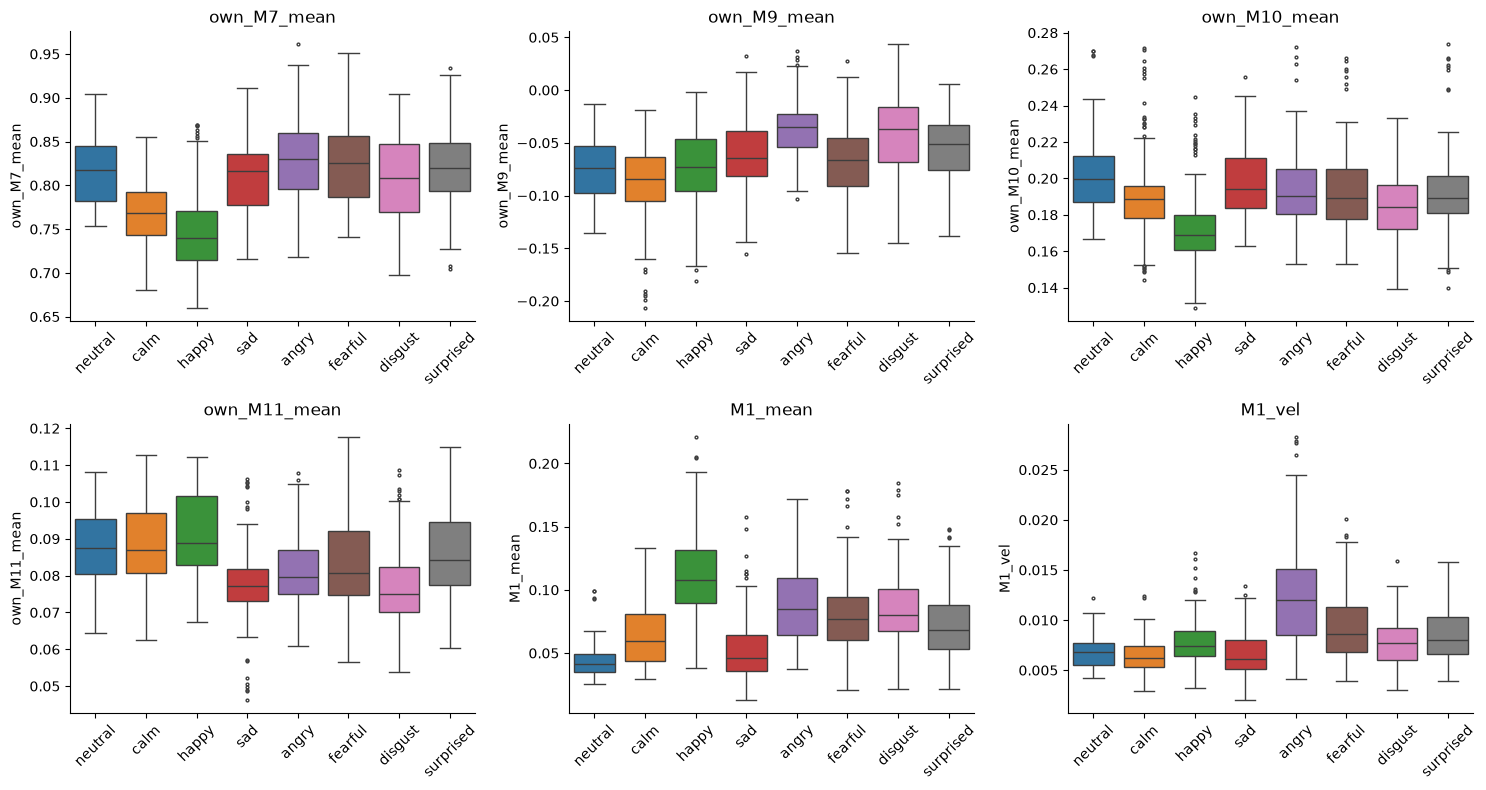

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, features_33):
    sns.boxplot(data=table_33, x="emotion", y=feature, order=order,
                hue="emotion", hue_order=order, palette="tab10", legend=False,
                fliersize=2, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

**Figure: distribution of six features per emotion.** One panel per feature, each with its own vertical axis; one box per emotion, in the same order and colour in every panel. An emotion is separated when its box is shifted from the others, and confused when the boxes overlap.

In [11]:
quartiles = table_33.groupby("emotion")[features_33].quantile([0.25, 0.5, 0.75])
quartiles.loc[order].round(4)  # rows: emotion x quartile

own_M7_mean  own_M9_mean  own_M10_mean  own_M11_mean  M1_mean  \
emotion                                                                         
neutral   0.25       0.7817      -0.0978        0.1871        0.0805   0.0351   
          0.50       0.8180      -0.0738        0.1995        0.0874   0.0417   
          0.75       0.8453      -0.0531        0.2125        0.0952   0.0494   
calm      0.25       0.7427      -0.1055        0.1783        0.0807   0.0441   
          0.50       0.7688      -0.0843        0.1887        0.0870   0.0594   
          0.75       0.7924      -0.0639        0.1958        0.0969   0.0810   
happy     0.25       0.7150      -0.0953        0.1604        0.0829   0.0893   
          0.50       0.7393      -0.0725        0.1689        0.0888   0.1080   
          0.75       0.7706      -0.0463        0.1798        0.1017   0.1317   
sad       0.25       0.7770      -0.0815        0.1837        0.0732   0.0360   
          0.50       0.8161      -0.0647        0.1942        0.0771   0.0464   
          0.75       0.8360      -0.0392        0.2115        0.0819   0.0642   
angry     0.25       0.7960      -0.0536        0.1804        0.0751   0.0639   
          0.50       0.8300      -0.0352        0.1901        0.0797   0.0852   
          0.75       0.8602      -0.0226        0.2052        0.0870   0.1096   
fearful   0.25       0.7861      -0.0911        0.1778        0.0747   0.0606   
          0.50       0.8259      -0.0664        0.1891        0.0807   0.0769   
          0.75       0.8559      -0.0455        0.2053        0.0921   0.0945   
disgust   0.25       0.7699      -0.0679        0.1720        0.0701   0.0673   
          0.50       0.8087      -0.0372        0.1841        0.0749   0.0802   
          0.75       0.8475      -0.0159        0.1966        0.0824   0.1010   
surprised 0.25       0.7936      -0.0760        0.1809        0.0774   0.0532   
          0.50       0.8200      -0.0513        0.1893        0.0841   0.0685   
          0.75       0.8480      -0.0332        0.2013        0.0945   0.0877   

                M1_vel  
emotion                 
neutral   0.25  0.0055  
          0.50  0.0068  
          0.75  0.0077  
calm      0.25  0.0053  
          0.50  0.0062  
          0.75  0.0074  
happy     0.25  0.0064  
          0.50  0.0074  
          0.75  0.0089  
sad       0.25  0.0052  
          0.50  0.0062  
          0.75  0.0080  
angry     0.25  0.0085  
          0.50  0.0120  
          0.75  0.0151  
fearful   0.25  0.0069  
          0.50  0.0086  
          0.75  0.0113  
disgust   0.25  0.0060  
          0.50  0.0077  
          0.75  0.0092  
surprised 0.25  0.0066  
          0.50  0.0080  
          0.75  0.0103

**Table: quartiles of the six features per emotion.** For each emotion, the first quartile (0.25), the median (0.5) and the third quartile (0.75) of each feature over its videos. The values are compared within each column (between emotions), never between columns, because each feature has its own scale.

### Answer to Q3.3

We call two emotions **separated** by a feature when their boxes do not overlap, and **confused** when their boxes overlap. This compares the middle 50 % of the videos of each emotion: even when two boxes are apart, the whiskers can overlap, so some videos of the two emotions still have similar values.

**`own_M7_mean` (expected lower for happy): holds.** It separates happy (median 0.739, against 0.81 to 0.83) from most emotions, but confuses it with calm (0.769); the other six emotions are confused with each other.

**`own_M9_mean` (expected higher for angry): holds in part.** Angry is the highest (−0.035), but disgust is at the same level (−0.037), so it confuses the two; both are separated from calm, the lowest (−0.084).

**`own_M10_mean` (expected lower for disgust): does not hold.** The lowest is happy (0.169), not disgust (0.184): a smile also lifts the upper lip, so M10 separates happy, like M7, and confuses disgust with the rest.

**`own_M11_mean` (expected higher for surprised, lower for fearful): does not hold.** It only splits the emotions into two overlapping groups, neutral, calm, happy and surprised higher, and sad, angry, fearful and disgust lower, and separates no single emotion.

**`M1_mean` (mouth opening).** It separates happy, the highest (0.108), from neutral (0.042) and sad (0.046), which it confuses with each other; surprised is not the highest, probably because the actors speak in every video.

**`M1_vel` (how fast the mouth opening changes).** It separates angry, which moves the mouth the most (0.0120), from neutral, calm and sad, but confuses it with fearful and surprised; it is the only movement feature, and it singles out an emotion the position features did not.

**Overall.** No feature separates all eight emotions, and each one separates at most one or two of them. Fearful and surprised are confused by all six features, and neutral and sad by five of them (only M11 moves them apart, and only in part: their boxes still touch).